# SALA — Step 05: Learning Automaton (Core)

**Goal:** Build the associative Learning Automaton (L_R-I) and integrate it
with the outputs of the anomaly detector (Step 03) and the sentiment analyzer
(Step 04).

**Why this matters:**
This is the **brain** of SALA. It learns, over many days, which of the two
sources (sentiment vs. price knowledge) is more reliable in each market state.

**Plan:**
1. Test the standalone L_R-I automaton on synthetic data.
2. Test the associative L_R-I automaton on synthetic contexts.
3. Prepare a unified dataset for BTC-USD: return + anomaly flag + sentiment.
4. Run the associative automaton day by day.
5. Compare vs. two baselines.

**Inputs:**
- `data/processed/BTC-USD.csv`
- `data/processed/sentiment_daily.csv`

**Outputs:**
- `results/tables/automaton_probs_btc.csv`
- `results/tables/automaton_log_btc.csv`
- `results/tables/automaton_performance.csv`
- `results/figures/05_lri_synthetic.png`
- `results/figures/05_associative_synthetic.png`
- `results/figures/05_automaton_performance.png`

In [16]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not find project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.config import PROCESSED_DIR, FIGURES_DIR, TABLES_DIR
from src.automaton.learning_automaton import LearningAutomaton
from src.automaton.associative_la import AssociativeLearningAutomaton

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed dir: {PROCESSED_DIR}")

Project root: /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)
Processed dir: /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)/data/processed


## 2. Sanity check: standalone L_R-I

Test that the L_R-I rule learns to prefer a better action on synthetic data.
Action A1 is "good" with probability 0.7; A2 with 0.3.

After 1000 trials:
  p(A1) = 1.0000   (should be close to 1.0)
  p(A2) = 0.0000


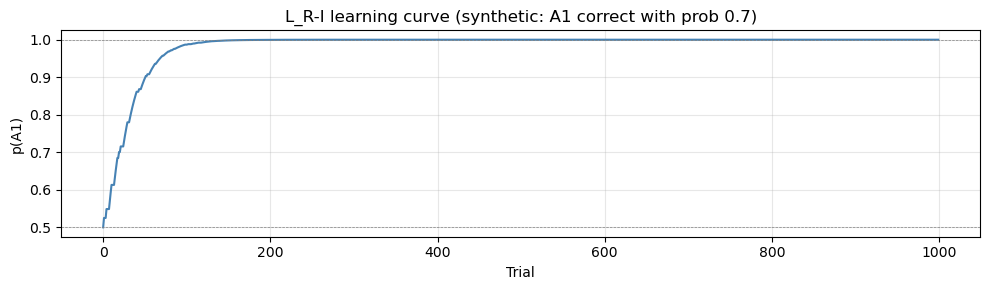

Figure saved: 05_lri_synthetic.png


In [17]:
rng = np.random.default_rng(42)
la = LearningAutomaton(learning_rate=0.05, init_prob=0.5, seed=42)

p1_history = []
n_trials = 1000
reward_probs = [0.7, 0.3]

for t in range(n_trials):
    action = la.choose_action()
    reward = rng.random() < reward_probs[action]
    la.update(action, reward)
    p1_history.append(la.p[0])

print(f"After {n_trials} trials:")
print(f"  p(A1) = {la.p[0]:.4f}   (should be close to 1.0)")
print(f"  p(A2) = {la.p[1]:.4f}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(p1_history, color="steelblue")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=0.5)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.5)
ax.set_xlabel("Trial")
ax.set_ylabel("p(A1)")
ax.set_title("L_R-I learning curve (synthetic: A1 correct with prob 0.7)")
ax.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURES_DIR / "05_lri_synthetic.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")

## 3. Sanity check: associative L_R-I

Two contexts with opposite best actions:
- Context A: A1 good (0.8), A2 bad (0.2)
- Context B: A1 bad (0.2), A2 good (0.8)

The associative automaton should learn a different policy for each context.

After training:
  Context A: p(A1) = 1.000
  Context B: p(A1) = 0.000

Expected: Context A -> high p(A1), Context B -> low p(A1)


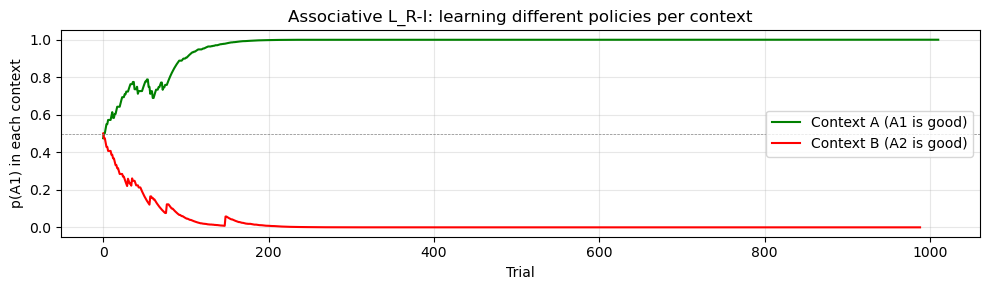

Figure saved: 05_associative_synthetic.png


In [18]:
ala = AssociativeLearningAutomaton(learning_rate=0.05, init_prob=0.5, seed=42)

contexts = ["A", "B"]
reward_probs_by_context = {
    "A": [0.8, 0.2],
    "B": [0.2, 0.8],
}

p1_by_context = {"A": [], "B": []}
n_trials = 2000

for t in range(n_trials):
    ctx = rng.choice(contexts)
    action = ala.choose_action(ctx)
    reward = rng.random() < reward_probs_by_context[ctx][action]
    ala.update(ctx, action, reward)
    p1_by_context[ctx].append(ala.get_probabilities(ctx)[0])

print("After training:")
for ctx in contexts:
    print(f"  Context {ctx}: p(A1) = {ala.get_probabilities(ctx)[0]:.3f}")
print()
print("Expected: Context A -> high p(A1), Context B -> low p(A1)")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(p1_by_context["A"], label="Context A (A1 is good)", color="green")
ax.plot(p1_by_context["B"], label="Context B (A2 is good)", color="red")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.5)
ax.set_xlabel("Trial")
ax.set_ylabel("p(A1) in each context")
ax.set_title("Associative L_R-I: learning different policies per context")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURES_DIR / "05_associative_synthetic.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")

## 4. Load real data (BTC-USD)

Load the processed price data and the daily sentiment series. Verify that
the sentiment file has ~1440 rows (not 30).

In [19]:
btc = pd.read_csv(PROCESSED_DIR / "BTC-USD.csv", index_col="Date", parse_dates=True)
sent = pd.read_csv(PROCESSED_DIR / "sentiment_daily.csv", parse_dates=["Date"]).set_index("Date")

print(f"BTC rows: {len(btc)}")
print(f"Sentiment rows: {len(sent)}")
print(f"Sentiment range: {sent.index.min().date()} -> {sent.index.max().date()}")
print()
print(sent["Sentiment_Label"].value_counts())

BTC rows: 1460
Sentiment rows: 1440
Sentiment range: 2022-01-21 -> 2025-12-30

Sentiment_Label
negative    711
positive    460
neutral     269
Name: count, dtype: int64


## 5. Build the SALA dataset

Combine price + sentiment into a single DataFrame with a **Context** for each day:
- Sentiment_Label: `positive` or `negative` (neutral → positive for simplicity)
- Anomaly: 0 or 1
- Context: `(sentiment_label, anomaly)`

Drop the warm-up rows (Z_Score NaN).

In [20]:
def classify_sentiment(score: float) -> str:
    return "positive" if score >= 0 else "negative"

sent_daily = sent["Sentiment_Score"].reindex(btc.index, method="ffill").fillna(0.0)
sent_label = sent_daily.apply(classify_sentiment)

btc_work = btc.copy()
btc_work["Sentiment_Score"] = sent_daily
btc_work["Sentiment_Label"] = sent_label
btc_work["Anomaly"] = btc_work["Is_Anomaly"].astype(int)
btc_work["Context"] = list(zip(btc_work["Sentiment_Label"], btc_work["Anomaly"]))

btc_work = btc_work.dropna(subset=["Z_Score"]).copy()
btc_work = btc_work.reset_index()

print(f"Working rows: {len(btc_work)}")
print()
print("Context distribution:")
print(btc_work["Context"].value_counts())
btc_work.head()

Working rows: 1440

Context distribution:
Context
(negative, 0)    756
(positive, 0)    648
(negative, 1)     21
(positive, 1)     15
Name: count, dtype: int64


,Date,Close,High,Low,Open,Volume,Return,Rolling_Mean,Rolling_Std,Z_Score,Is_Anomaly,Sentiment_Score,Sentiment_Label,Anomaly,Context
0,2022-01-21,36457.316406,41060.527344,35791.425781,40699.605469,43011992031,-0.103812,-0.012925,0.028776,-3.158443,1,-0.584767,negative,1,"(negative, 1)"
1,2022-01-22,35030.250000,36688.812500,34349.250000,36471.589844,39714385405,-0.039143,-0.014524,0.029322,-0.839625,0,0.276133,positive,0,"(positive, 0)"
2,2022-01-23,36276.804688,36433.312500,34784.968750,35047.359375,26017975951,0.035585,-0.011808,0.031357,1.511411,0,0.278700,positive,0,"(positive, 0)"
3,2022-01-24,36654.328125,37247.519531,33184.058594,36275.734375,41856658597,0.010407,-0.010684,0.031747,0.664339,0,-0.008600,negative,0,"(negative, 0)"
4,2022-01-25,36954.003906,37444.570312,35779.429688,36654.804688,26428189594,0.008176,-0.007739,0.030546,0.521000,0,0.579900,positive,0,"(positive, 0)"


## 6. Define the reward rule

- `A1` (trust sentiment): buy if sentiment positive, sell if negative.
- `A2` (trust anomaly): buy if no anomaly, sell if anomaly.
- Reward: True if next-day return matches the chosen direction.

In [21]:
def decide(action: int, sentiment_label: str, anomaly: int) -> str:
    if action == 0:
        return "up" if sentiment_label == "positive" else "down"
    else:
        return "down" if anomaly == 1 else "up"


ala = AssociativeLearningAutomaton(learning_rate=0.05, init_prob=0.5, seed=42)

log = []
for i in range(len(btc_work) - 1):
    row = btc_work.iloc[i]
    ctx = row["Context"]
    action = ala.choose_action(ctx)
    direction = decide(action, row["Sentiment_Label"], int(row["Anomaly"]))

    ret_next = btc_work.iloc[i + 1]["Return"]
    if pd.isna(ret_next):
        continue

    reward = (direction == "up" and ret_next > 0) or (direction == "down" and ret_next < 0)
    ala.update(ctx, action, reward)

    log.append({
        "Date": row["Date"],
        "Context": ctx,
        "Action": action,
        "Direction": direction,
        "Next_Return": ret_next,
        "Reward": int(reward),
        "p_A1": ala.get_probabilities(ctx)[0],
    })

log_df = pd.DataFrame(log)
print(f"Simulated {len(log_df)} trades")
print()
print("Final probabilities per context:")
for ctx in sorted(ala.known_contexts(), key=str):
    p = ala.get_probabilities(ctx)
    print(f"  {ctx}:  p(A1)={p[0]:.3f}, p(A2)={p[1]:.3f}")
print()
print(f"Overall reward rate: {log_df['Reward'].mean():.3f}")
log_df.head()

Simulated 1439 trades

Final probabilities per context:
  ('negative', 0):  p(A1)=0.404, p(A2)=0.596
  ('negative', 1):  p(A1)=0.448, p(A2)=0.552
  ('positive', 0):  p(A1)=0.166, p(A2)=0.834
  ('positive', 1):  p(A1)=0.403, p(A2)=0.597

Overall reward rate: 0.487


,Date,Context,Action,Direction,Next_Return,Reward,p_A1
0,2022-01-21,"(negative, 1)",0,down,-0.039143,1,0.52500
1,2022-01-22,"(positive, 0)",0,up,0.035585,1,0.52500
2,2022-01-23,"(positive, 0)",0,up,0.010407,1,0.54875
3,2022-01-24,"(negative, 0)",1,up,0.008176,1,0.47500
4,2022-01-25,"(positive, 0)",1,up,-0.002757,0,0.54875


## 7. Save results

In [22]:
TABLES_DIR.mkdir(parents=True, exist_ok=True)

probs_rows = [
    {"Context": str(ctx), "p_A1_trust_sentiment": p[0], "p_A2_trust_anomaly": p[1]}
    for ctx in ala.known_contexts()
    for p in [ala.get_probabilities(ctx)]
]
pd.DataFrame(probs_rows).to_csv(TABLES_DIR / "automaton_probs_btc.csv", index=False)

log_df.to_csv(TABLES_DIR / "automaton_log_btc.csv", index=False)

print("Saved: automaton_probs_btc.csv")
print("Saved: automaton_log_btc.csv")

Saved: automaton_probs_btc.csv
Saved: automaton_log_btc.csv


## 8. Compare vs. two baselines

                  Policy  Reward_Rate
SALA (associative L_R-I)     0.487144
  Always trust sentiment     0.498958
    Always trust anomaly     0.501042

Saved: automaton_performance.csv


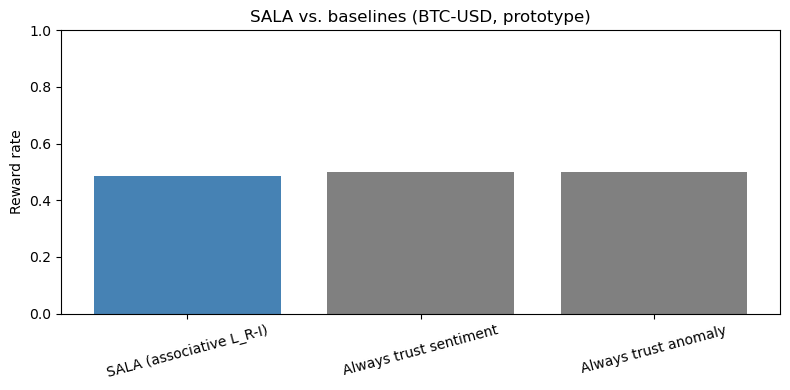

Figure saved: 05_automaton_performance.png


In [23]:
def run_fixed(action: int) -> float:
    rewards = []
    for i in range(len(btc_work) - 1):
        row = btc_work.iloc[i]
        direction = decide(action, row["Sentiment_Label"], int(row["Anomaly"]))
        ret_next = btc_work.iloc[i + 1]["Return"]
        if pd.isna(ret_next):
            continue
        rewards.append(int((direction == "up" and ret_next > 0) or (direction == "down" and ret_next < 0)))
    return float(np.mean(rewards)) if rewards else 0.0


results = pd.DataFrame([
    {"Policy": "SALA (associative L_R-I)",  "Reward_Rate": log_df["Reward"].mean()},
    {"Policy": "Always trust sentiment",    "Reward_Rate": run_fixed(0)},
    {"Policy": "Always trust anomaly",      "Reward_Rate": run_fixed(1)},
])
print(results.to_string(index=False))

results.to_csv(TABLES_DIR / "automaton_performance.csv", index=False)
print()
print("Saved: automaton_performance.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(results["Policy"], results["Reward_Rate"], color=["steelblue", "gray", "gray"])
ax.set_ylabel("Reward rate")
ax.set_title("SALA vs. baselines (BTC-USD, prototype)")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

fig_path = FIGURES_DIR / "05_automaton_performance.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")